# <center>Hybrid Search RAG | Chapter 5 </center>
## BM25 (Best Matching 25)

## Learning flow

```text
Why TF-IDF is not enough
        ↓
BM25 intuition
        ↓
BM25 formula
        ↓
IDF
        ↓
TF saturation
        ↓
k1
        ↓
Document-length normalization
        ↓
b and avgdl
        ↓
Manual BM25
        ↓
BM25 from scratch
        ↓
BM25 vs TF-IDF
        ↓
Parameter experiments
        ↓
Failure cases
        ↓
Hybrid Search connection
```

## Core mental model

```text
TF-IDF:
"More repeats = more weight"

BM25:
"More repeats help, but only up to a point."

TF-IDF:
"Document length is only indirectly handled."

BM25:
"Long documents are explicitly normalized."
```

# 0. How to Study This Notebook

For each topic:

```text
Read the idea
   ↓
Look at the diagram
   ↓
Predict the result
   ↓
Run the code
   ↓
Read printed internals
   ↓
Check the visualization
   ↓
Answer the checkpoint
   ↓
Verify with the provided answer
```

Do not memorize the full BM25 formula first. Understand why each part exists.

In [1]:
import math
import re
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

print("Setup complete.")

Setup complete.


# 1. Simple Corpus

We use only simple examples.

```text
D1: cat drinks milk
D2: cat cat drinks milk
D3: dog eats food
D4: cat eats fish
D5: apple banana fruit salad
D6: apple apple fruit
```

In [2]:
documents = {
    "D1": "cat drinks milk",
    "D2": "cat cat drinks milk",
    "D3": "dog eats food",
    "D4": "cat eats fish",
    "D5": "apple banana fruit salad",
    "D6": "apple apple fruit",
}

def tokenize(text):
    return re.findall(r"[a-z0-9]+", text.lower())

for doc_id, text in documents.items():
    print(f"{doc_id}: {text}")

D1: cat drinks milk
D2: cat cat drinks milk
D3: dog eats food
D4: cat eats fish
D5: apple banana fruit salad
D6: apple apple fruit


# 2. Why Do We Need BM25?

TF-IDF is useful, but two issues matter in real search.

## Problem A — Repetition

```text
D1: cat
D2: cat cat
D3: cat cat cat cat cat cat cat cat cat cat
```

Raw TF treats ten occurrences as ten times the count of one occurrence.

But relevance usually behaves more like:

```text
1st occurrence  → strong evidence
2nd occurrence  → useful
3rd occurrence  → useful
10th occurrence → only a little extra
```

BM25 solves this using **term-frequency saturation**.

## Problem B — Document length

Compare:

```text
D1: cat milk

D2: cat milk + 100 unrelated words
```

D1 is more focused. BM25 explicitly normalizes for document length.

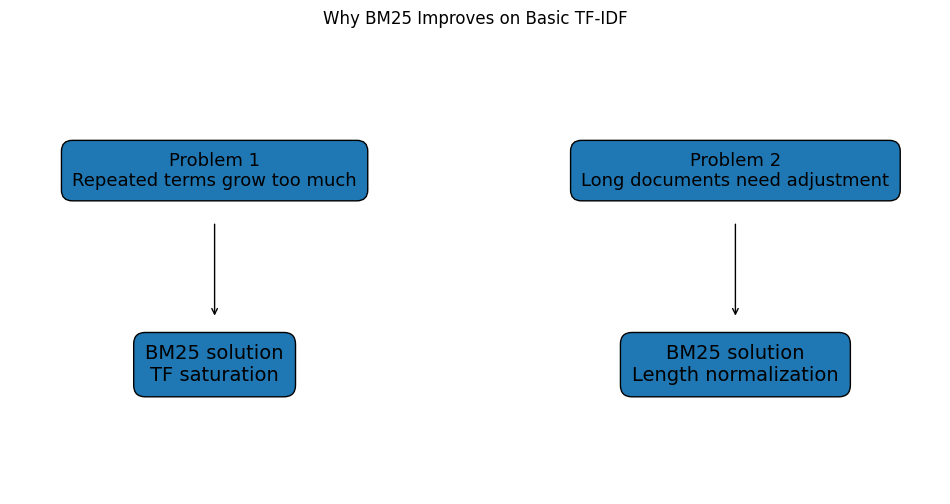

In [3]:
fig, ax = plt.subplots(figsize=(12, 6))
ax.axis("off")

ax.text(0.22, 0.70, "Problem 1\nRepeated terms grow too much",
        ha="center", va="center", fontsize=13,
        bbox=dict(boxstyle="round,pad=0.6"))
ax.text(0.78, 0.70, "Problem 2\nLong documents need adjustment",
        ha="center", va="center", fontsize=13,
        bbox=dict(boxstyle="round,pad=0.6"))
ax.text(0.22, 0.28, "BM25 solution\nTF saturation",
        ha="center", va="center", fontsize=14,
        bbox=dict(boxstyle="round,pad=0.6"))
ax.text(0.78, 0.28, "BM25 solution\nLength normalization",
        ha="center", va="center", fontsize=14,
        bbox=dict(boxstyle="round,pad=0.6"))

ax.annotate("", xy=(0.22,0.38), xytext=(0.22,0.59), arrowprops=dict(arrowstyle="->"))
ax.annotate("", xy=(0.78,0.38), xytext=(0.78,0.59), arrowprops=dict(arrowstyle="->"))

plt.title("Why BM25 Improves on Basic TF-IDF")
plt.show()

# 3. BM25 Intuition

For every query term, BM25 asks:

```text
Is the term present?
        ↓
How rare is it?        → IDF
        ↓
How often does it occur? → TF
        ↓
Has repetition saturated? → k1
        ↓
Is the document long/short? → b + |D| / avgdl
        ↓
Term score
```

For multi-word queries, BM25 sums the term scores.

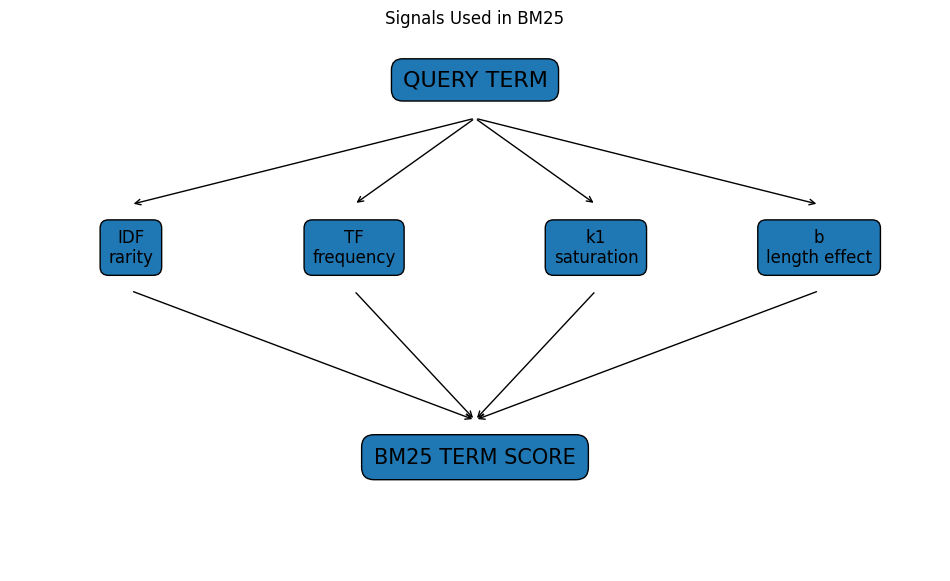

In [4]:
fig, ax = plt.subplots(figsize=(12, 7))
ax.axis("off")

ax.text(0.5,0.90,"QUERY TERM",ha="center",fontsize=16,bbox=dict(boxstyle="round,pad=0.5"))
items=[(0.13,"IDF\nrarity"),(0.37,"TF\nfrequency"),(0.63,"k1\nsaturation"),(0.87,"b\nlength effect")]
for x,label in items:
    ax.text(x,0.60,label,ha="center",va="center",fontsize=12,bbox=dict(boxstyle="round,pad=0.5"))
    ax.annotate("",xy=(x,0.68),xytext=(0.5,0.84),arrowprops=dict(arrowstyle="->"))
ax.text(0.5,0.20,"BM25 TERM SCORE",ha="center",fontsize=15,bbox=dict(boxstyle="round,pad=0.6"))
for x,_ in items:
    ax.annotate("",xy=(0.5,0.28),xytext=(x,0.52),arrowprops=dict(arrowstyle="->"))
plt.title("Signals Used in BM25")
plt.show()

# 4. The BM25 Formula

A common form is:


$$
BM25(D,Q)
=
\sum_{q_i \in Q}
IDF(q_i)
\cdot
\frac{
TF(q_i,D)(k_1+1)
}{
TF(q_i,D)+
k_1\left(
1-b+b\frac{|D|}{avgdl}
\right)
}
$$

### Symbols

```text
TF(q,D)  = count of query term q in document D
IDF(q)   = rarity of q across documents
k1       = TF saturation control
b        = document-length normalization control
|D|      = current document length
avgdl    = average document length in corpus
```

# 5. Corpus Statistics

BM25 needs:

```text
N      = number of documents
DF     = document frequency of each term
|D|    = current document length
avgdl  = average document length
```

In [5]:
tokenized = {doc_id: tokenize(text) for doc_id, text in documents.items()}
doc_lengths = {doc_id: len(tokens) for doc_id, tokens in tokenized.items()}
N = len(documents)
avgdl = sum(doc_lengths.values()) / N

print("N =", N)
print("Document lengths =", doc_lengths)
print("avgdl =", avgdl)

N = 6
Document lengths = {'D1': 3, 'D2': 4, 'D3': 3, 'D4': 3, 'D5': 4, 'D6': 3}
avgdl = 3.3333333333333335


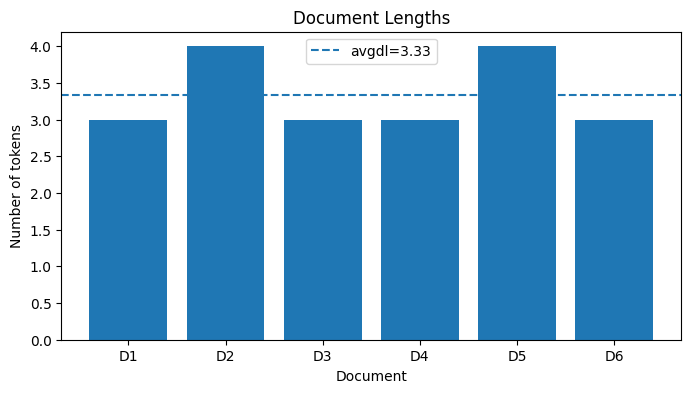

In [6]:
plt.figure(figsize=(8,4))
plt.bar(list(doc_lengths.keys()), list(doc_lengths.values()))
plt.axhline(avgdl, linestyle="--", label=f"avgdl={avgdl:.2f}")
plt.ylabel("Number of tokens")
plt.xlabel("Document")
plt.title("Document Lengths")
plt.legend()
plt.show()

# 6. Document Frequency and BM25 IDF

BM25 needs DF:

```text
DF(term) = number of documents containing the term
```

A common BM25 IDF formula is:

$$
IDF(q) = \log\left(
1 + \frac{N - DF(q) + 0.5}{DF(q) + 0.5}
\right)
$$

Rare term:

```text
small DF → larger IDF
```

Common term:

```text
large DF → smaller IDF
```

In [7]:
vocabulary = sorted({term for toks in tokenized.values() for term in toks})

df_map = {}
for term in vocabulary:
    df_map[term] = sum(1 for toks in tokenized.values() if term in set(toks))

def bm25_idf(term):
    df = df_map.get(term, 0)
    return math.log(1 + (N - df + 0.5) / (df + 0.5))

rows=[]
for term in vocabulary:
    rows.append({"term":term,"df":df_map[term],"idf":bm25_idf(term)})

idf_table=pd.DataFrame(rows).sort_values("idf",ascending=False)
display(idf_table)

,term,df,idf
1,banana,1,1.540445
3,dog,1,1.540445
6,fish,1,1.540445
7,food,1,1.540445
10,salad,1,1.540445
0,apple,2,1.029619
4,drinks,2,1.029619
5,eats,2,1.029619
8,fruit,2,1.029619
9,milk,2,1.029619


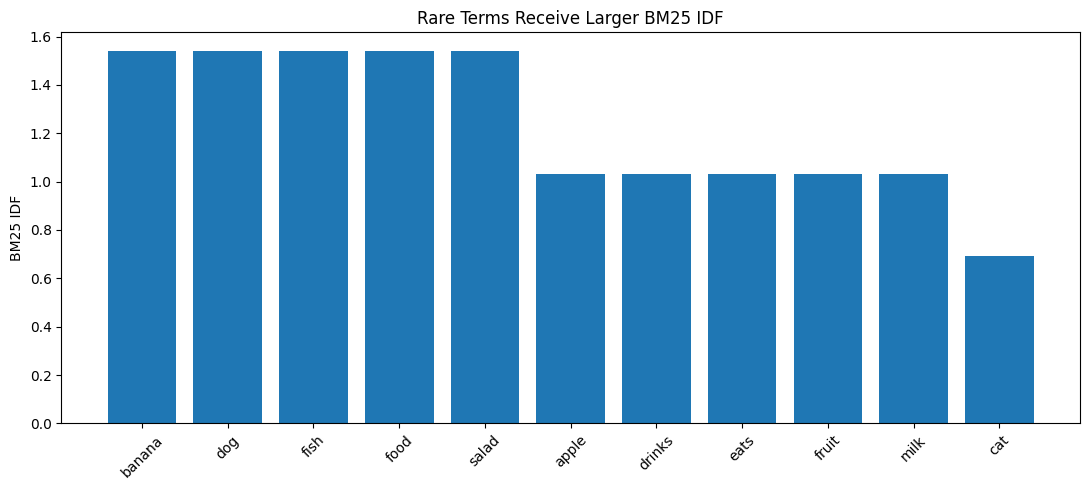

In [8]:
plt.figure(figsize=(11,5))
plt.bar(idf_table["term"], idf_table["idf"])
plt.xticks(rotation=45)
plt.ylabel("BM25 IDF")
plt.title("Rare Terms Receive Larger BM25 IDF")
plt.tight_layout()
plt.show()

# CHECKPOINT 1

### Questions

1. What is `avgdl`?
2. Why does BM25 need DF?
3. What does IDF represent?
4. Why are rare terms useful?

## Answers

1. `avgdl` is the average number of tokens per document in the corpus.
2. DF is needed to determine how common or rare a query term is.
3. IDF is the rarity/discriminative importance of a term across the corpus.
4. Rare terms narrow the search space more strongly, so they usually provide stronger evidence of relevance.

# 7. Term-Frequency Saturation

BM25 does **not** allow repeated terms to grow relevance linearly forever.

Think:

```text
TF=1  → strong first signal
TF=2  → more evidence
TF=5  → still useful
TF=20 → not 20× more relevant
```

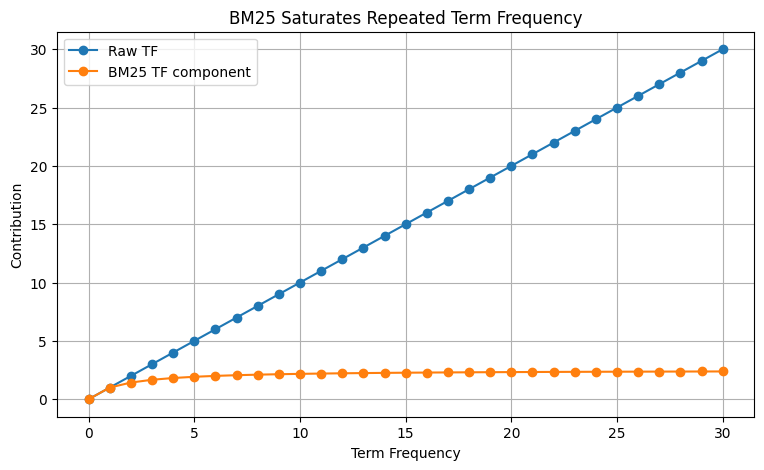

In [9]:
def tf_component(tf, k1=1.5, b=0.0, doc_length=10, avgdl=10):
    numerator = tf * (k1 + 1)
    denominator = tf + k1 * (1 - b + b * (doc_length / avgdl))
    return 0 if denominator == 0 else numerator / denominator

tf_values=np.arange(0,31)
raw=tf_values
sat=[tf_component(tf=x,k1=1.5,b=0.0) for x in tf_values]

plt.figure(figsize=(9,5))
plt.plot(tf_values,raw,marker="o",label="Raw TF")
plt.plot(tf_values,sat,marker="o",label="BM25 TF component")
plt.xlabel("Term Frequency")
plt.ylabel("Contribution")
plt.title("BM25 Saturates Repeated Term Frequency")
plt.legend()
plt.grid(True)
plt.show()

# 8. The `k1` Parameter

`k1` controls how quickly TF saturation happens.

```text
smaller k1 → saturation happens sooner
larger k1  → repetitions keep helping longer
```

A common range is roughly:

```text
1.2 to 2.0
```

but it should be tuned on evaluation data.

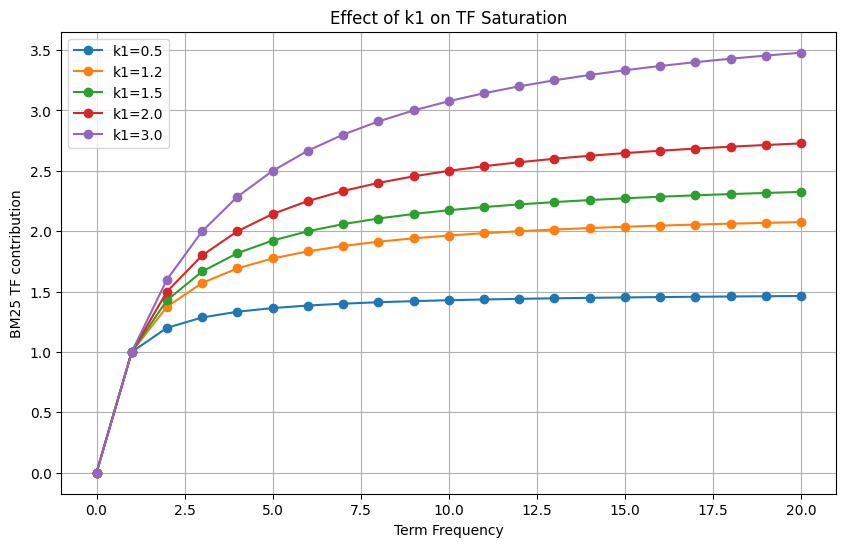

In [10]:
tf_values=np.arange(0,21)
k1_values=[0.5,1.2,1.5,2.0,3.0]

plt.figure(figsize=(10,6))
for k1 in k1_values:
    values=[tf_component(tf=x,k1=k1,b=0.0) for x in tf_values]
    plt.plot(tf_values,values,marker="o",label=f"k1={k1}")

plt.xlabel("Term Frequency")
plt.ylabel("BM25 TF contribution")
plt.title("Effect of k1 on TF Saturation")
plt.legend()
plt.grid(True)
plt.show()

### Visual intuition

```text
LOW k1
│
├─ 1st repeat matters
├─ 2nd repeat helps
└─ saturation quickly

HIGH k1
│
├─ 1st repeat matters
├─ 2nd repeat matters
├─ 3rd repeat still matters
└─ saturation later
```

# 9. Document-Length Normalization

Compare:

```text
Short:
cat milk

Long:
cat milk dog food book table chair apple banana orange ...
```

Both contain the same query terms.

But the short document is much more focused.

BM25 uses:

$$
\frac{|D|}{avgdl}
$$

to tell whether the document is shorter or longer than average.

In [11]:
example_lengths=[5,10,20,40]
example_avgdl=10

length_table=pd.DataFrame({
    "doc_length":example_lengths,
    "avgdl":[example_avgdl]*len(example_lengths),
    "length_ratio":[L/example_avgdl for L in example_lengths]
})
display(length_table)

,doc_length,avgdl,length_ratio
0,5,10,0.5
1,10,10,1.0
2,20,10,2.0
3,40,10,4.0


# 10. The `b` Parameter

`b` controls how much document length matters.

```text
b = 0
→ ignore length

b = 0.75
→ strong but not complete normalization

b = 1
→ full length normalization
```

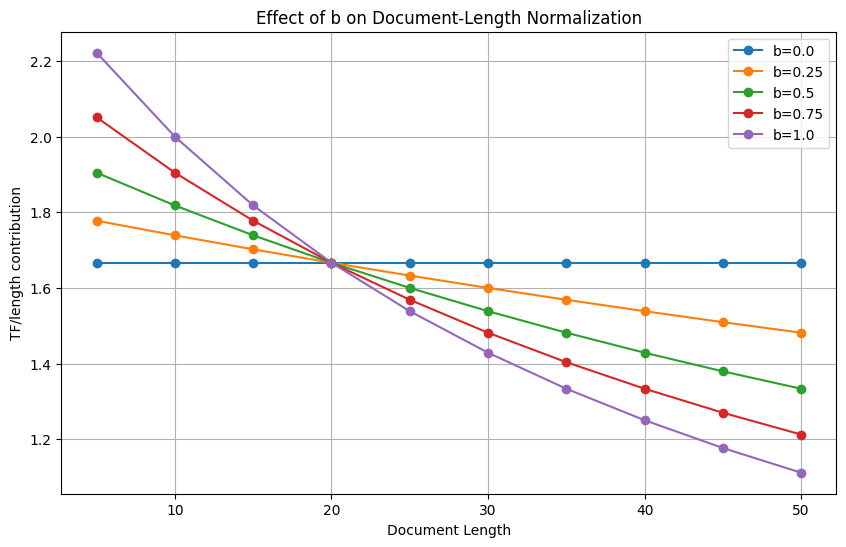

In [12]:
def term_score_without_idf(tf, doc_length, avgdl, k1=1.5, b=0.75):
    return tf*(k1+1)/(tf+k1*(1-b+b*(doc_length/avgdl)))

doc_lengths_x=np.arange(5,51,5)
b_values=[0.0,0.25,0.5,0.75,1.0]

plt.figure(figsize=(10,6))
for b in b_values:
    vals=[term_score_without_idf(3,L,20,k1=1.5,b=b) for L in doc_lengths_x]
    plt.plot(doc_lengths_x,vals,marker="o",label=f"b={b}")

plt.xlabel("Document Length")
plt.ylabel("TF/length contribution")
plt.title("Effect of b on Document-Length Normalization")
plt.legend()
plt.grid(True)
plt.show()

# CHECKPOINT 2

### Questions

1. What is TF saturation?
2. What does `k1` control?
3. What does `b` control?
4. What happens when `b=0`?
5. What happens when `b=1`?

## Answers

1. TF saturation means repeated occurrences help less and less as frequency grows.
2. `k1` controls how quickly repeated-term contribution saturates.
3. `b` controls the strength of document-length normalization.
4. At `b=0`, document length is ignored.
5. At `b=1`, full document-length normalization is applied.

# 11. Manual BM25 Calculation

Let's calculate the score contribution for:

```text
Query term: cat
Document: D2 = cat cat drinks milk
k1 = 1.5
b  = 0.75
```

We will print every step.

In [13]:
def manual_bm25_term(term, doc_id, k1=1.5, b=0.75):
    tf=Counter(tokenized[doc_id])[term]
    df=df_map.get(term,0)
    idf=math.log(1+(N-df+0.5)/(df+0.5))
    dl=doc_lengths[doc_id]
    ratio=dl/avgdl
    length_factor=1-b+b*ratio
    numerator=tf*(k1+1)
    denominator=tf+k1*length_factor
    saturated_tf=numerator/denominator if denominator else 0
    score=idf*saturated_tf

    print("TERM:",term)
    print("DOCUMENT:",doc_id,documents[doc_id])
    print("\n1. TF =",tf)
    print("2. DF =",df)
    print("3. N =",N)
    print("4. IDF =",idf)
    print("5. |D| =",dl)
    print("6. avgdl =",avgdl)
    print("7. |D|/avgdl =",ratio)
    print("8. length factor =",length_factor)
    print("9. numerator =",numerator)
    print("10. denominator =",denominator)
    print("11. saturated TF =",saturated_tf)
    print("12. final term score =",score)

    return score

manual_bm25_term("cat","D2")

TERM: cat
DOCUMENT: D2 cat cat drinks milk

1. TF = 2
2. DF = 3
3. N = 6
4. IDF = 0.6931471805599453
5. |D| = 4
6. avgdl = 3.3333333333333335
7. |D|/avgdl = 1.2
8. length factor = 1.15
9. numerator = 5.0
10. denominator = 3.7249999999999996
11. saturated TF = 1.342281879194631
12. final term score = 0.9303989000804636


0.9303989000804636

# 12. Multi-Term Query

For:

```text
Query: cat milk
```

BM25 calculates:

```text
BM25(cat, document)
+
BM25(milk, document)
```

and sums the contributions.

```text
            cat              milk
             │                 │
             ▼                 ▼
       term score         term score
             │                 │
             └────────┬────────┘
                      ▼
               TOTAL SCORE
```

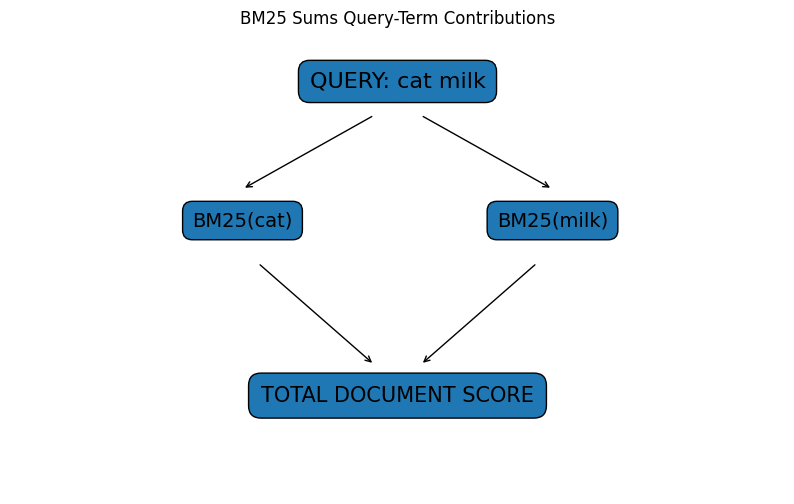

In [14]:
fig,ax=plt.subplots(figsize=(10,6))
ax.axis("off")
ax.text(0.5,0.88,"QUERY: cat milk",ha="center",fontsize=16,bbox=dict(boxstyle="round,pad=0.5"))
ax.text(0.3,0.58,"BM25(cat)",ha="center",fontsize=14,bbox=dict(boxstyle="round,pad=0.5"))
ax.text(0.7,0.58,"BM25(milk)",ha="center",fontsize=14,bbox=dict(boxstyle="round,pad=0.5"))
ax.text(0.5,0.2,"TOTAL DOCUMENT SCORE",ha="center",fontsize=15,bbox=dict(boxstyle="round,pad=0.6"))
ax.annotate("",xy=(0.3,0.66),xytext=(0.47,0.82),arrowprops=dict(arrowstyle="->"))
ax.annotate("",xy=(0.7,0.66),xytext=(0.53,0.82),arrowprops=dict(arrowstyle="->"))
ax.annotate("",xy=(0.47,0.28),xytext=(0.32,0.50),arrowprops=dict(arrowstyle="->"))
ax.annotate("",xy=(0.53,0.28),xytext=(0.68,0.50),arrowprops=dict(arrowstyle="->"))
plt.title("BM25 Sums Query-Term Contributions")
plt.show()

# 13. BM25 From Scratch

Now we implement the full retrieval algorithm.

```text
Corpus preprocessing
      ↓
DF + document lengths + avgdl
      ↓
Query
      ↓
For every document:
    for every query term:
        TF
        IDF
        saturation
        length normalization
        term score
    sum
      ↓
Sort scores
      ↓
Top-K
```

In [15]:
class SimpleBM25:
    def __init__(self, documents, k1=1.5, b=0.75):
        self.documents=documents
        self.k1=k1
        self.b=b
        self.tokenized={d:tokenize(t) for d,t in documents.items()}
        self.doc_ids=list(documents.keys())
        self.N=len(self.doc_ids)
        self.doc_lengths={d:len(toks) for d,toks in self.tokenized.items()}
        self.avgdl=sum(self.doc_lengths.values())/self.N

        vocab={term for toks in self.tokenized.values() for term in toks}
        self.df={
            term:sum(1 for toks in self.tokenized.values() if term in set(toks))
            for term in vocab
        }

        print("BM25 initialized")
        print("N =",self.N)
        print("avgdl =",self.avgdl)
        print("k1 =",self.k1)
        print("b =",self.b)

    def idf(self,term):
        df=self.df.get(term,0)
        return math.log(1+(self.N-df+0.5)/(df+0.5))

    def score_document(self,query,doc_id,verbose=False):
        q_terms=tokenize(query)
        counts=Counter(self.tokenized[doc_id])
        dl=self.doc_lengths[doc_id]
        total=0.0

        if verbose:
            print("\n"+"="*70)
            print("DOCUMENT:",doc_id)
            print("TEXT:",self.documents[doc_id])

        for term in q_terms:
            tf=counts[term]
            if tf==0:
                if verbose: print(f"{term}: absent → 0")
                continue

            idf=self.idf(term)
            length_factor=1-self.b+self.b*(dl/self.avgdl)
            tf_part=tf*(self.k1+1)/(tf+self.k1*length_factor)
            term_score=idf*tf_part
            total+=term_score

            if verbose:
                print(f"\nTERM: {term}")
                print("TF =",tf)
                print("DF =",self.df.get(term,0))
                print("IDF =",idf)
                print("doc length =",dl)
                print("length factor =",length_factor)
                print("TF component =",tf_part)
                print("term score =",term_score)

        if verbose:
            print("TOTAL =",total)
        return total

    def search(self,query,top_k=5,verbose=False):
        rows=[]
        print("\nQUERY:",query)

        for doc_id in self.doc_ids:
            score=self.score_document(query,doc_id,verbose)
            rows.append({"doc_id":doc_id,"text":self.documents[doc_id],"score":score})

        result=pd.DataFrame(rows).sort_values("score",ascending=False).head(top_k)
        display(result)
        return result

In [16]:
bm25=SimpleBM25(documents,k1=1.5,b=0.75)

result=bm25.search(
    "cat milk",
    top_k=6,
    verbose=True
)

BM25 initialized
N = 6
avgdl = 3.3333333333333335
k1 = 1.5
b = 0.75

QUERY: cat milk

DOCUMENT: D1
TEXT: cat drinks milk

TERM: cat
TF = 1
DF = 3
IDF = 0.6931471805599453
doc length = 3
length factor = 0.9249999999999999
TF component = 1.0471204188481675
term score = 0.7258085660313564

TERM: milk
TF = 1
DF = 2
IDF = 1.0296194171811581
doc length = 3
length factor = 0.9249999999999999
TF component = 1.0471204188481675
term score = 1.0781355153729404
TOTAL = 1.8039440814042966

DOCUMENT: D2
TEXT: cat cat drinks milk

TERM: cat
TF = 2
DF = 3
IDF = 0.6931471805599453
doc length = 4
length factor = 1.15
TF component = 1.342281879194631
term score = 0.9303989000804636

TERM: milk
TF = 1
DF = 2
IDF = 1.0296194171811581
doc length = 4
length factor = 1.15
TF component = 0.9174311926605506
term score = 0.9446049698909709
TOTAL = 1.8750038699714344

DOCUMENT: D3
TEXT: dog eats food
cat: absent → 0
milk: absent → 0
TOTAL = 0.0

DOCUMENT: D4
TEXT: cat eats fish

TERM: cat
TF = 1
DF = 3
IDF = 0.69

,doc_id,text,score
1,D2,cat cat drinks milk,1.875004
0,D1,cat drinks milk,1.803944
3,D4,cat eats fish,0.725809
2,D3,dog eats food,0.000000
4,D5,apple banana fruit salad,0.000000
5,D6,apple apple fruit,0.000000


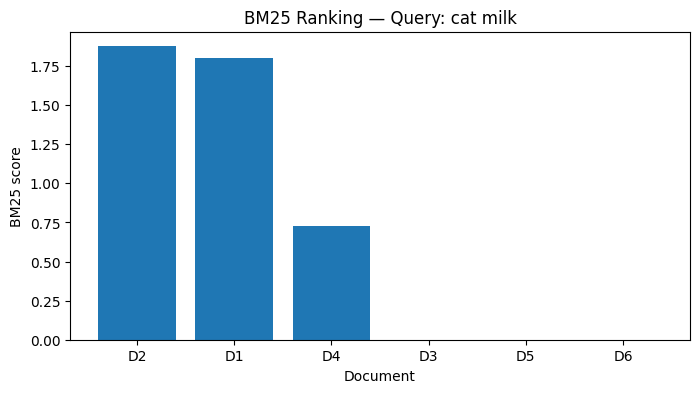

In [17]:
plt.figure(figsize=(8,4))
plt.bar(result["doc_id"],result["score"])
plt.ylabel("BM25 score")
plt.xlabel("Document")
plt.title("BM25 Ranking — Query: cat milk")
plt.show()

# 14. Experiment — TF Saturation With Real Documents

```text
D1: apple
D2: apple apple
D3: apple × 4
D4: apple × 10
```

Prediction:

```text
scores increase,
but not linearly
```

BM25 initialized
N = 4
avgdl = 4.25
k1 = 1.5
b = 0.0

QUERY: apple


,doc_id,text,score
3,D4,apple apple apple apple apple apple apple appl...,0.229045
2,D3,apple apple apple apple,0.191565
1,D2,apple apple,0.150515
0,D1,apple,0.105361


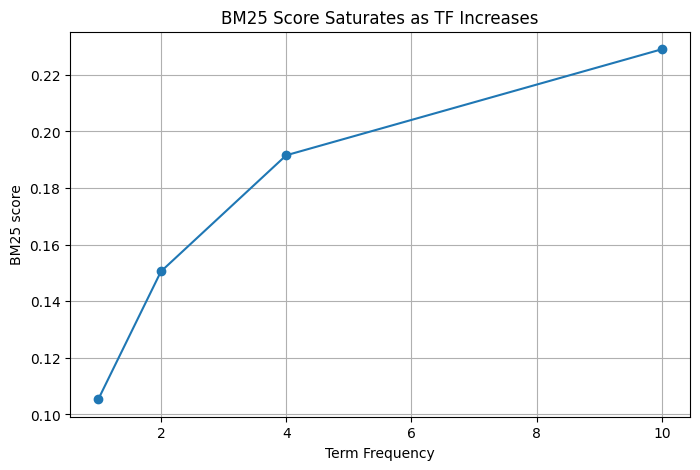

In [18]:
repeat_docs={
    "D1":"apple",
    "D2":"apple apple",
    "D3":"apple apple apple apple",
    "D4":"apple apple apple apple apple apple apple apple apple apple"
}

repeat_model=SimpleBM25(repeat_docs,k1=1.5,b=0.0)
repeat_result=repeat_model.search("apple",top_k=4)

tf_counts=[1,2,4,10]
scores=[repeat_model.score_document("apple",d) for d in ["D1","D2","D3","D4"]]

plt.figure(figsize=(8,5))
plt.plot(tf_counts,scores,marker="o")
plt.xlabel("Term Frequency")
plt.ylabel("BM25 score")
plt.title("BM25 Score Saturates as TF Increases")
plt.grid(True)
plt.show()

# 15. Experiment — Short vs Long Documents

All documents contain:

```text
cat milk
```

but with different amounts of unrelated content.

BM25 initialized
N = 3
avgdl = 10.333333333333334
k1 = 1.5
b = 0.75

QUERY: cat milk

DOCUMENT: Short
TEXT: cat milk

TERM: cat
TF = 1
DF = 3
IDF = 0.13353139262452257
doc length = 2
length factor = 0.3951612903225806
TF component = 1.5696202531645569
term score = 0.20959357829671896

TERM: milk
TF = 1
DF = 3
IDF = 0.13353139262452257
doc length = 2
length factor = 0.3951612903225806
TF component = 1.5696202531645569
term score = 0.20959357829671896
TOTAL = 0.4191871565934379

DOCUMENT: Medium
TEXT: cat milk dog food book table

TERM: cat
TF = 1
DF = 3
IDF = 0.13353139262452257
doc length = 6
length factor = 0.6854838709677419
TF component = 1.2326043737574552
term score = 0.1645913785829105

TERM: milk
TF = 1
DF = 3
IDF = 0.13353139262452257
doc length = 6
length factor = 0.6854838709677419
TF component = 1.2326043737574552
term score = 0.1645913785829105
TOTAL = 0.329182757165821

DOCUMENT: Long
TEXT: cat milk dog food book table chair apple banana orange school pen pencil paper wate

,doc_id,text,score
0,Short,cat milk,0.419187
1,Medium,cat milk dog food book table,0.329183
2,Long,cat milk dog food book table chair apple banan...,0.172119


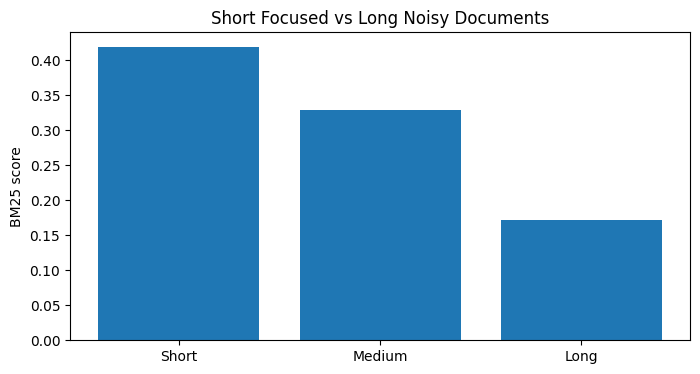

In [19]:
length_docs={
    "Short":"cat milk",
    "Medium":"cat milk dog food book table",
    "Long":"cat milk dog food book table chair apple banana orange school pen pencil paper water bird fish house road tree green blue red"
}

length_model=SimpleBM25(length_docs,k1=1.5,b=0.75)
length_result=length_model.search("cat milk",top_k=3,verbose=True)

plt.figure(figsize=(8,4))
plt.bar(length_result["doc_id"],length_result["score"])
plt.ylabel("BM25 score")
plt.title("Short Focused vs Long Noisy Documents")
plt.show()

# 16. Experiment — What Happens When `b = 0`?

At `b=0`, length normalization is disabled.

Let's compare:

```text
b = 0
vs
b = 0.75
```

BM25 initialized
N = 3
avgdl = 10.333333333333334
k1 = 1.5
b = 0.0
BM25 initialized
N = 3
avgdl = 10.333333333333334
k1 = 1.5
b = 0.75


,doc_id,b=0,b=0.75
0,Short,0.267063,0.419187
1,Medium,0.267063,0.329183
2,Long,0.267063,0.172119


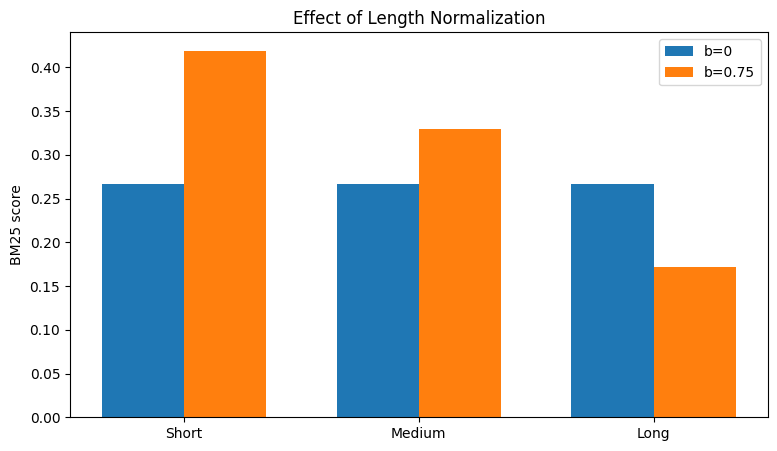

In [20]:
model_b0=SimpleBM25(length_docs,k1=1.5,b=0.0)
model_b75=SimpleBM25(length_docs,k1=1.5,b=0.75)

rows=[]
for doc_id in length_docs:
    rows.append({
        "doc_id":doc_id,
        "b=0":model_b0.score_document("cat milk",doc_id),
        "b=0.75":model_b75.score_document("cat milk",doc_id)
    })

b_compare=pd.DataFrame(rows)
display(b_compare)

x=np.arange(len(b_compare))
w=0.35
plt.figure(figsize=(9,5))
plt.bar(x-w/2,b_compare["b=0"],w,label="b=0")
plt.bar(x+w/2,b_compare["b=0.75"],w,label="b=0.75")
plt.xticks(x,b_compare["doc_id"])
plt.ylabel("BM25 score")
plt.title("Effect of Length Normalization")
plt.legend()
plt.show()

# CHECKPOINT 3

### Questions

1. Why does BM25 not grow linearly with TF?
2. Why can a short focused document beat a long noisy document?
3. Why does `b=0` remove the length penalty?
4. Why does BM25 sum term scores?

## Answers

1. BM25 uses TF saturation, so each additional repetition contributes less.
2. The length-normalization factor penalizes unusually long documents when `b > 0`.
3. The length-dependent part is multiplied by `b`; at zero, it disappears.
4. A multi-term query provides multiple pieces of lexical evidence, so BM25 adds them.

# 17. BM25 vs TF-IDF

| Capability | TF-IDF | BM25 |
|---|---|---|
| Exact term matching | Yes | Yes |
| Rare-term weighting | Yes | Yes |
| TF saturation | Limited | **Yes** |
| Explicit length normalization | Limited | **Yes** |
| Sparse lexical retrieval | Yes | Yes |
| Semantic understanding | No | No |

Both are lexical.

BM25 is generally the stronger retrieval baseline for search.

# 18. Compare Rankings on the Same Corpus

Query:

```text
cat milk
```

Important:

> TF-IDF cosine scores and BM25 scores use different scales.

Compare rankings or normalized scores, not raw magnitudes.

In [ ]:
doc_ids=list(documents.keys())
texts=list(documents.values())

vec=TfidfVectorizer()
tfidf_matrix=vec.fit_transform(texts)
q=vec.transform(["cat milk"])
tfidf_scores=cosine_similarity(q,tfidf_matrix).flatten()

bm25_scores=[bm25.score_document("cat milk",d) for d in doc_ids]

compare=pd.DataFrame({
    "doc_id":doc_ids,
    "tfidf":tfidf_scores,
    "bm25":bm25_scores
})
display(compare)

tfidf_norm=tfidf_scores/(tfidf_scores.max()+1e-12)
bm25_arr=np.array(bm25_scores)
bm25_norm=bm25_arr/(bm25_arr.max()+1e-12)

x=np.arange(len(doc_ids)); w=0.35
plt.figure(figsize=(10,5))
plt.bar(x-w/2,tfidf_norm,w,label="TF-IDF normalized")
plt.bar(x+w/2,bm25_norm,w,label="BM25 normalized")
plt.xticks(x,doc_ids)
plt.ylabel("Normalized score")
plt.title("TF-IDF vs BM25")
plt.legend()
plt.show()

# 19. Tune `k1`

Let's see how the score of a high-TF document changes as `k1` changes.

In [ ]:
k1_values=[0.3,0.8,1.2,1.5,2.0,3.0]
rows=[]

for k1 in k1_values:
    m=SimpleBM25(repeat_docs,k1=k1,b=0.0)
    rows.append({"k1":k1,"score":m.score_document("apple","D4")})

k1_table=pd.DataFrame(rows)
display(k1_table)

plt.figure(figsize=(8,4))
plt.plot(k1_table["k1"],k1_table["score"],marker="o")
plt.xlabel("k1")
plt.ylabel("Score of high-TF document")
plt.title("Higher k1 Lets Repetition Matter More")
plt.grid(True)
plt.show()

# 20. Tune `b`

Let's see how short and long documents behave as `b` increases.

In [ ]:
b_values=[0.0,0.25,0.5,0.75,1.0]
rows=[]

for b in b_values:
    m=SimpleBM25(length_docs,k1=1.5,b=b)
    rows.append({
        "b":b,
        "short":m.score_document("cat milk","Short"),
        "long":m.score_document("cat milk","Long")
    })

b_table=pd.DataFrame(rows)
display(b_table)

plt.figure(figsize=(9,5))
plt.plot(b_table["b"],b_table["short"],marker="o",label="Short")
plt.plot(b_table["b"],b_table["long"],marker="o",label="Long")
plt.xlabel("b")
plt.ylabel("BM25 score")
plt.title("Increasing b Strengthens Length Normalization")
plt.legend()
plt.grid(True)
plt.show()

# 21. Optional: `rank_bm25` Library

After understanding the algorithm from scratch, you can use:

```text
rank_bm25
```

Install:

```python
%pip install rank-bm25
```

In [ ]:
# Uncomment if needed:
# %pip install -q rank-bm25

try:
    from rank_bm25 import BM25Okapi

    corpus_tokens=[tokenize(t) for t in documents.values()]
    lib_model=BM25Okapi(corpus_tokens)

    query_tokens=tokenize("cat milk")
    scores=lib_model.get_scores(query_tokens)

    lib_result=pd.DataFrame({
        "doc_id":list(documents.keys()),
        "text":list(documents.values()),
        "score":scores
    }).sort_values("score",ascending=False)

    display(lib_result)

except ImportError:
    print("rank_bm25 not installed. Run: %pip install rank-bm25")

# 22. BM25 Limitation — Vocabulary Mismatch

BM25 still matches **words**, not meanings.

Query:

```text
car repair
```

Document:

```text
automobile maintenance guide
```

Humans see a relationship.

BM25 does not inherently know:

```text
car ≈ automobile
repair ≈ maintenance
```

That is why dense retrieval is needed.

In [ ]:
syn_docs={
    "D1":"automobile maintenance guide",
    "D2":"car insurance policy",
    "D3":"bicycle repair manual"
}

syn_model=SimpleBM25(syn_docs)
syn_model.search("car repair",top_k=3)

# 23. BM25 Strength — Exact Terms

BM25 is particularly useful for:

```text
exact words
rare names
codes
IDs
versions
article numbers
technical terminology
```

Because lexical overlap is explicit and interpretable.

# 24. Why BM25 Is Excellent for Hybrid Search

```text
                USER QUERY
                    │
         ┌──────────┴──────────┐
         │                     │
         ▼                     ▼
       BM25                  DENSE
    exact words              meaning
    rare terms               synonyms
    IDs                      paraphrases
         │                     │
         └──────────┬──────────┘
                    ▼
                 FUSION
                    │
                    ▼
                  TOP-K
```

BM25 and dense retrieval fail in different ways.

That complementarity is the core reason Hybrid Search works.

In [ ]:
fig,ax=plt.subplots(figsize=(12,7))
ax.axis("off")
ax.text(0.5,0.90,"USER QUERY",ha="center",fontsize=16,bbox=dict(boxstyle="round,pad=0.5"))
ax.text(0.25,0.60,"BM25\nExact lexical signal",ha="center",va="center",fontsize=13,bbox=dict(boxstyle="round,pad=0.6"))
ax.text(0.75,0.60,"DENSE\nSemantic signal",ha="center",va="center",fontsize=13,bbox=dict(boxstyle="round,pad=0.6"))
ax.text(0.5,0.22,"FUSION → RERANKING → LLM",ha="center",fontsize=15,bbox=dict(boxstyle="round,pad=0.6"))
ax.annotate("",xy=(0.25,0.68),xytext=(0.47,0.84),arrowprops=dict(arrowstyle="->"))
ax.annotate("",xy=(0.75,0.68),xytext=(0.53,0.84),arrowprops=dict(arrowstyle="->"))
ax.annotate("",xy=(0.47,0.30),xytext=(0.27,0.52),arrowprops=dict(arrowstyle="->"))
ax.annotate("",xy=(0.53,0.30),xytext=(0.73,0.52),arrowprops=dict(arrowstyle="->"))
plt.title("BM25 + Dense = Complementary Retrieval")
plt.show()

# CHECKPOINT 4

### Questions

1. Why is BM25 still lexical retrieval?
2. Why is BM25 strong for exact IDs?
3. Why can BM25 fail on synonyms?
4. Why should raw TF-IDF and BM25 scores not be compared directly?
5. Why is BM25 useful in Hybrid Search?

## Answers

1. It scores exact query terms found in indexed document terms.
2. Exact IDs are highly discriminative lexical tokens.
3. BM25 does not inherently understand semantic equivalence between different words.
4. The scoring formulas and numerical ranges differ.
5. BM25 supplies exact lexical relevance while dense retrieval supplies semantic relevance.

# 25. BM25 Debugging Framework

If BM25 results look wrong, inspect:

```text
Query
 ↓
Tokenization
 ↓
Does term exist in vocabulary?
 ↓
TF in each document
 ↓
DF across corpus
 ↓
IDF
 ↓
Document length
 ↓
avgdl
 ↓
k1
 ↓
b
 ↓
Final term contributions
 ↓
Ranking
```

In [ ]:
def debug_bm25(model,query):
    print("="*80)
    print("BM25 DEBUG")
    print("="*80)
    print("Query:",query)
    terms=tokenize(query)
    print("Terms:",terms)
    print("avgdl:",model.avgdl)
    print("k1:",model.k1)
    print("b:",model.b)

    for term in terms:
        print("\nTERM:",term)
        print("DF:",model.df.get(term,0))
        print("IDF:",model.idf(term))
        for doc_id in model.doc_ids:
            print(
                doc_id,
                "TF=",Counter(model.tokenized[doc_id])[term],
                "length=",model.doc_lengths[doc_id]
            )

debug_bm25(bm25,"cat milk")

# 26. Interview Questions

### What is BM25?

A lexical ranking function that combines term rarity, term frequency saturation, and document-length normalization.

### Why is BM25 better than basic TF-IDF?

Because it explicitly handles:

```text
TF saturation
document-length normalization
```

### What is `k1`?

The parameter controlling how repeated-term contribution saturates.

### What is `b`?

The parameter controlling document-length normalization.

### What is `avgdl`?

Average document length in the corpus.

### Why use IDF?

Rare query terms usually provide stronger evidence of relevance.

### Why can BM25 miss semantic matches?

It matches lexical terms, not meaning.

### Why is BM25 important in Hybrid Search?

It complements dense semantic retrieval with strong exact lexical retrieval.

# 27. Interview Scenarios

### Scenario A

A word appears 100 times.

Should BM25 become 100× stronger?

**No.** TF saturation prevents linear growth.

### Scenario B

Two docs contain the same query terms, but one is much longer.

BM25 may prefer the shorter, more focused document because of length normalization.

### Scenario C

`b=0`.

Document length is ignored.

### Scenario D

Increase `k1`.

Repeated terms keep contributing for longer.

### Scenario E

Query: `car repair`, document: `automobile maintenance`.

BM25 may fail because of vocabulary mismatch.

### Scenario F

Why combine BM25 and dense retrieval?

```text
BM25 → exact lexical evidence
Dense → semantic evidence
```

# 28. One-Page Revision Map

```text
                    BM25
                     │
       ┌─────────────┼─────────────┐
       │             │             │
       ▼             ▼             ▼
      IDF            TF        DOC LENGTH
    rarity       frequency          │
       │             │              │
       │             ▼              ▼
       │         saturation     normalization
       │            k1              b
       │             │              │
       └─────────────┴───────┬──────┘
                             ▼
                        TERM SCORE
                             │
                             ▼
                     SUM QUERY TERMS
                             │
                             ▼
                          RANKING
                             │
                             ▼
                           TOP-K
```

$$
BM25(D,Q) =
\sum_{q_i \in Q}
IDF(q_i)
\frac{
TF(q_i,D)(k_1+1)
}{
TF(q_i,D)+k_1
\left(1-b+b\frac{|D|}{avgdl}\right)
}
$$

Remember:

```text
k1 → TF saturation
b  → length normalization
```

# 29. Practice Tasks

### Task 1
Create documents with TF values 1, 2, 4, 8, 16 and plot BM25 scores.

### Task 2
Repeat with `k1 = 0.5, 1.2, 2.0, 4.0`.

### Task 3
Create short and long documents with identical query terms. Compare `b = 0, 0.5, 1`.

### Task 4
Manually calculate one complete BM25 term score.

### Task 5
Implement BM25 without the class in this notebook.

### Task 6
Compare TF-IDF and BM25 rankings on 10 simple documents.

### Task 7
Create a synonym failure such as `car` vs `automobile`.

### Task 8
Use `rank_bm25` and compare the ranking with your own implementation.

# 30. Final Takeaways

1. BM25 is a lexical ranking algorithm.
2. It builds on the ideas behind TF-IDF.
3. IDF rewards rare query terms.
4. TF should not increase relevance forever.
5. BM25 uses TF saturation.
6. `k1` controls saturation.
7. BM25 normalizes document length.
8. `b` controls length normalization.
9. BM25 is strong for exact terms but weak for semantic vocabulary mismatch.
10. Hybrid Search combines BM25 with dense retrieval.

---

# Next Chapter — Chapter 6: Dense Retrieval

We will study:

```text
embeddings
dense vectors
semantic similarity
cosine similarity
dot product
Euclidean distance
query embeddings
document embeddings
bi-encoders
semantic neighborhoods
failure cases
exact-ID weakness
embedding-model selection
```